# Chapter 4 — The Original Finding: Did Competitive Elections Really Vanish?

The video that inspired this project says the number of truly contested House seats has "drastically reduced." That is a testable claim. So let's test it — on every U.S. House election from 1976 to 2024.

## Definitions, stated up front (so you can disagree with them honestly)

- **Margin:** in each district, the winner's votes minus the runner-up's votes, divided by all votes cast in that district, times 100. A 100-point margin means the race was uncontested.
- **Competitive:** a margin of **5 percentage points or less**. That threshold is our choice, not a law of nature.
- We count only the 50 states (the District of Columbia's delegate doesn't vote), only general elections, and only regular (non-special) elections.
- One candidate can appear on several party lines (New York's fusion system), so votes are summed per candidate before ranking.

## Data

MIT Election Data + Science Lab district returns: the TidyTuesday mirror (1976–2022, clean CSV) plus the 2024 point from the MIT 1976–2024 file (Harvard Dataverse DOI 10.7910/DVN/IG0UN2; direct download blocked by a guestbook form, so a public mirror is used and cross-checked — it reproduces the 2016 and 2020 North Carolina results exactly and yields 435 seats for 2024).

A few years cover fewer than 435 seats in this file (1992: 427, 1996: 425, 2006: 431). Shares below are computed over the seats covered.


In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import os
import io
import csv
import pandas as pd
import matplotlib.pyplot as plt

DATA = '../data/raw'
STATES = set('AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split())


def load_tidytuesday():
    path = os.path.join(DATA, 'house_tidytuesday_1976_2022.csv')
    if not os.path.exists(path):
        import urllib.request
        url = ('https://raw.githubusercontent.com/rfordatascience/tidytuesday/'
               'master/data/2023/2023-11-07/house.csv')
        print('Downloading TidyTuesday MIT file...')
        urllib.request.urlretrieve(url, path)
    return pd.read_csv(path, low_memory=False)


def load_mirror_2024():
    """Tolerant reader for the quoted-rows mirror of the MIT 1976-2024 file.

    Quirk, documented honestly: every row is wrapped in quotation marks and
    56 of 33,805 rows are malformed (extra commas inside a field). We skip
    those rows and cross-check the result (435 seats for 2024).
    """
    path = os.path.join(DATA, 'house_1976_2024.csv')
    if not os.path.exists(path):
        import urllib.request
        url = ('https://raw.githubusercontent.com/keithpotz/Election-Prediction/'
               'main/src/data/polling_data/house_1976_2024.csv')
        print('Downloading MIT 1976-2024 mirror file...')
        urllib.request.urlretrieve(url, path)
    with open(path, newline='') as f:
        lines = f.readlines()
    header = lines[0].strip().split(',')
    rows, skipped = [], 0
    for ln in lines[1:]:
        s = ln.strip()
        if s.startswith('"') and s.endswith('"'):
            s = s[1:-1]
        try:
            r = next(csv.reader(io.StringIO(s)))
        except Exception:
            skipped += 1
            continue
        if len(r) != 20:
            skipped += 1
            continue
        rows.append(r)
    print(f'Mirror file: {len(rows)} rows parsed, {skipped} malformed rows skipped')
    return pd.DataFrame(rows, columns=header)


tt = load_tidytuesday()
print('TidyTuesday rows:', len(tt), '| years:', int(tt['year'].min()), '-', int(tt['year'].max()))
mirror = load_mirror_2024()
mirror24 = mirror[mirror['year'].astype(str) == '2024']
print('Mirror 2024 rows:', len(mirror24))

TidyTuesday rows: 32452 | years: 1976 - 2022
Mirror file: 33749 rows parsed, 56 malformed rows skipped


Mirror 2024 rows: 1330


## Step 1 — Compute the margin of every district, every year

For each district-year we rank the candidates, take the top two, and compute the margin. Then we aggregate: how many seats were decided by 5 points or less?


In [3]:
def yearly_table(frame):
    """One row per election year: seats covered, competitive seats, competitive share."""
    df = frame[(frame['office'] == 'US HOUSE') & (frame['stage'] == 'GEN')
                & (frame['special'].astype(str).str.upper() == 'FALSE')
                & (frame['state_po'].isin(STATES))].copy()
    df['candidatevotes'] = pd.to_numeric(df['candidatevotes'], errors='coerce')
    df['totalvotes'] = pd.to_numeric(df['totalvotes'], errors='coerce')
    df = df.dropna(subset=['candidatevotes'])
    cand = df.groupby(['year', 'state_po', 'district', 'candidate'],
                      as_index=False)['candidatevotes'].sum()
    tot = df.groupby(['year', 'state_po', 'district'],
                     as_index=False)['totalvotes'].first()
    m = cand.merge(tot, on=['year', 'state_po', 'district'])
    out = []
    for y, sub in m.groupby('year'):
        margins = []
        for _, d in sub.groupby(['state_po', 'district']):
            v = d.sort_values('candidatevotes', ascending=False)['candidatevotes'].values
            t = d['totalvotes'].iloc[0]
            if pd.isna(t) or t <= 0:
                t = v.sum()
            margins.append((v[0] - (v[1] if len(v) > 1 else 0)) / t * 100 if t else 100.0)
        ms = pd.Series(margins)
        out.append({'year': int(y), 'seats': len(ms),
                    'competitive': int((ms <= 5).sum()),
                    'competitive_share': (ms <= 5).mean() * 100})
    return pd.DataFrame(out)


table = yearly_table(tt)
table24 = yearly_table(mirror24)
table = pd.concat([table, table24], ignore_index=True).sort_values('year')
table.to_csv('../data/processed/competitive_share_by_year.csv', index=False)
print(table.to_string(index=False))
print()
print('Saved to data/processed/competitive_share_by_year.csv')

 year  seats  competitive  competitive_share
 1976    435           36           8.275862
 1978    435           30           6.896552
 1980    435           39           8.965517
 1982    435           35           8.045977
 1984    435           28           6.436782
 1986    435           25           5.747126
 1988    435           16           3.678161
 1990    435           29           6.666667
 1992    435           44          10.114943
 1994    435           47          10.804598
 1996    425           40           9.411765
 1998    435           17           3.908046
 2000    435           19           4.367816
 2002    435           23           5.287356
 2004    435           10           2.298851
 2006    431           35           8.120650
 2008    435           26           5.977011
 2010    435           39           8.965517
 2012    435           31           7.126437
 2014    435           24           5.517241
 2016    435           16           3.678161
 2018    4

## Step 2 — The headline chart: competitive seats over time

Read it carefully. This is the moment this project gets interesting — and more honest than the video.


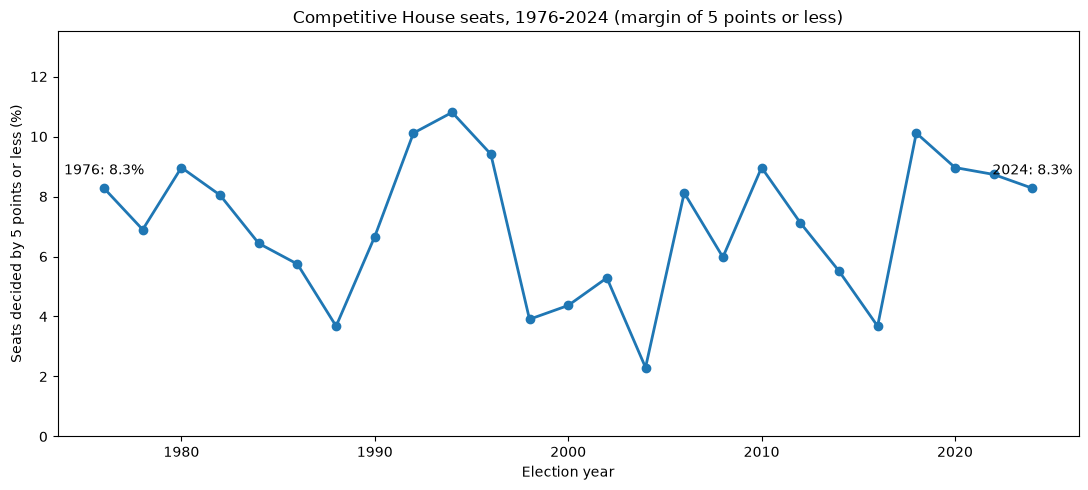

Chart saved to charts/phase4_competitive_share.png


In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(table['year'], table['competitive_share'], marker='o', linewidth=2)
ax.set_xlabel('Election year')
ax.set_ylabel('Seats decided by 5 points or less (%)')
ax.set_title('Competitive House seats, 1976-2024 (margin of 5 points or less)')
ax.set_ylim(0, max(table['competitive_share']) * 1.25)
for y, s in [(1976, table.iloc[0]['competitive_share']),
             (2024, table.iloc[-1]['competitive_share'])]:
    ax.annotate(f'{y}: {s:.1f}%', (y, s), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('../charts/phase4_competitive_share.png', dpi=150)
plt.show()
print('Chart saved to charts/phase4_competitive_share.png')

## What the chart actually says — read this before you repeat the video's claim

**The competitive share does NOT decline.** It bounces between about 2% and 11%, spiking in wave years (1994, 2010, 2018) and collapsing in quiet years (2004, 1988, 2016). By the narrow "last election's margin" definition, close races still happen — they just come in waves.

So is the video wrong? Not exactly — but its claim needs a qualifier. The famous "vanishing competition" finding in the research literature is usually measured differently: by **presidential partisanship of the district** (how red or blue a district votes for president) or by expert ratings, not by the last House margin. Those need presidential votes by district, which are not in this file. What this file *can* show is something else that changed — and it is striking. Read on.


## Step 3 — A second lens: the seats–votes gap

For each year, compare the Democratic share of the **two-party vote** with the Democratic share of **seats**. In a perfectly proportional system the two lines would match. When they don't, the map itself is leaning — or the electoral system is rewarding one party's geography.


In [5]:
def seats_votes(frame):
    df = frame[(frame['office'] == 'US HOUSE') & (frame['stage'] == 'GEN')
                & (frame['special'].astype(str).str.upper() == 'FALSE')
                & (frame['state_po'].isin(STATES))
                & (frame['party'].isin(['DEMOCRAT', 'REPUBLICAN']))].copy()
    df['candidatevotes'] = pd.to_numeric(df['candidatevotes'], errors='coerce')
    df = df.dropna(subset=['candidatevotes'])
    out = []
    for y, sub in df.groupby('year'):
        v = sub.groupby('party')['candidatevotes'].sum()
        d_vote = v.get('DEMOCRAT', 0) / (v.get('DEMOCRAT', 0) + v.get('REPUBLICAN', 0)) * 100
        cand = sub.groupby(['state_po', 'district', 'candidate'],
                           as_index=False)['candidatevotes'].sum()
        win = cand.loc[cand.groupby(['state_po', 'district'])['candidatevotes'].idxmax()]
        parties = sub.drop_duplicates(['state_po', 'district', 'candidate']).merge(
            win[['state_po', 'district', 'candidate']],
            on=['state_po', 'district', 'candidate'])
        d_seat = (parties['party'] == 'DEMOCRAT').mean() * 100
        out.append({'year': int(y), 'd_vote': d_vote, 'd_seat': d_seat,
                    'gap': d_seat - d_vote})
    return pd.DataFrame(out)


sv = seats_votes(tt)
sv24 = seats_votes(mirror24)
sv = pd.concat([sv, sv24], ignore_index=True).sort_values('year')
print(sv.round(1).to_string(index=False))

 year  d_vote  d_seat  gap
 1976    57.1    66.9  9.8
 1978    54.4    63.9  9.5
 1980    51.3    56.3  5.0
 1982    56.0    61.8  5.8
 1984    52.6    58.4  5.8
 1986    55.0    59.5  4.5
 1988    53.3    58.6  5.3
 1990    53.4    60.0  6.6
 1992    52.7    59.0  6.3
 1994    45.8    45.7 -0.0
 1996    50.4    48.5 -1.9
 1998    48.7    47.1 -1.6
 2000    49.1    48.0 -1.1
 2002    46.7    46.2 -0.5
 2004    48.0    45.5 -2.4
 2006    53.7    53.4 -0.3
 2008    54.9    57.9  3.0
 2010    46.4    45.3 -1.1
 2012    50.2    46.2 -4.0
 2014    46.4    42.5 -3.9
 2016    49.3    44.6 -4.7
 2018    53.7    53.6 -0.2
 2020    51.3    51.0 -0.3
 2022    48.4    49.7  1.3
 2024    48.1    48.7  0.6


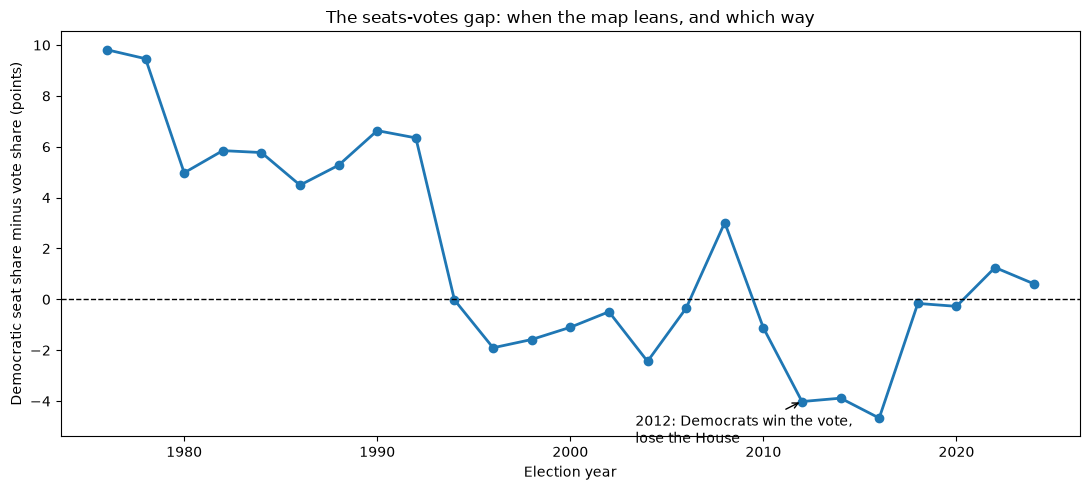

Chart saved to charts/phase4_seats_votes_gap.png


In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sv['year'], sv['gap'], marker='o', linewidth=2)
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.set_xlabel('Election year')
ax.set_ylabel('Democratic seat share minus vote share (points)')
ax.set_title('The seats-votes gap: when the map leans, and which way')
ax.annotate('2012: Democrats win the vote,\nlose the House', (2012, -4.0),
            textcoords='offset points', xytext=(-120, -30),
            arrowprops=dict(arrowstyle='->'), fontsize=10)
plt.tight_layout()
plt.savefig('../charts/phase4_seats_votes_gap.png', dpi=150)
plt.show()
print('Chart saved to charts/phase4_seats_votes_gap.png')

## What the gap chart says — the finding this project actually stands on

- **1976–1992:** Democrats consistently won *more* seats than their vote share (+5 to +10 points). That was the old map era.
- **1994–2010:** roughly proportional — the gap hovers near zero.
- **2012, 2014, 2016:** the gap flips to about **−4 points**. In 2012, Democrats won the national House vote and still lost the chamber (201 seats to 234). That is the fingerprint of the post-2010 redistricting cycle.
- **2018–2024:** back near proportional.

So the honest story is subtler than the video's slogan — and stronger for it: **competition didn't vanish from the margins, but the map's thumb on the scale flipped sides after 2010, and in 2012 it produced a wrong-winner House.** A recruiter would rather hear that sentence, backed by two charts, than a slogan.

## Checkpoint — what you now know

- How to test a viral claim against 24 elections of real data — and how to report it when the data complicates the claim.
- That "competitive" depends on the definition, and definitions must be stated up front.
- That the seats–votes gap is a second, independent lens on the same question — and it shows a real break after 2010.

Next chapter (optional, advanced): can statistics prove a single map is rigged? We generate 1,000 alternative maps and see where the real one falls.
